In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_context('paper', font_scale=1.7, rc={'axes.linewidth': 1.3, 'lines.linewidth': 2.5, 'patch.linewidth': 2.2})
sns.set_style('ticks', {'xtick.direction': 'in', 'ytick.direction': 'in'})
plt.rcParams.update({'xtick.labelsize': 17, 'ytick.labelsize': 17, 'axes.labelsize': 20,
                     'axes.linewidth': 1.5, 'font.family': 'serif'})

In [2]:
cat = np.load('ellip_centrals_z0_PIG817_sfr200_catalog.npy')
bhs = np.load('ellip_centrals_z0_PIG817_sfr200_bhs.npy')
halo = np.load('ellip_centrals_z0_PIG817_sfr200_halo_r200.npy')

h = 0.6774
M_bh_max = 3e5 / h

gal = cat[cat['dispersion_dominated']]
wand = bhs[bhs['dispersion_dominated'] & (bhs['rank_mass_in_gal'] > 0) & (bhs['bh_mass'] < M_bh_max)]
r200 = halo['r200_kpc'][np.searchsorted(halo['subidx'], wand['gal_subidx'])]
x_r200 = wand['dist_kpc'] / r200

bins = [1, 2, 3]
label = {1: r'$M_\star = 10^{9}\!-\!10^{10}\,M_\odot$', 2: r'$M_\star = 10^{10}\!-\!10^{11}\,M_\odot$', 3: r'$M_\star > 10^{11}\,M_\odot$'}
color = {1: '#008300', 2: '#e34948', 3: '#2a78d6'}
ngal = {b: np.sum(gal['massbin'] == b) for b in bins}

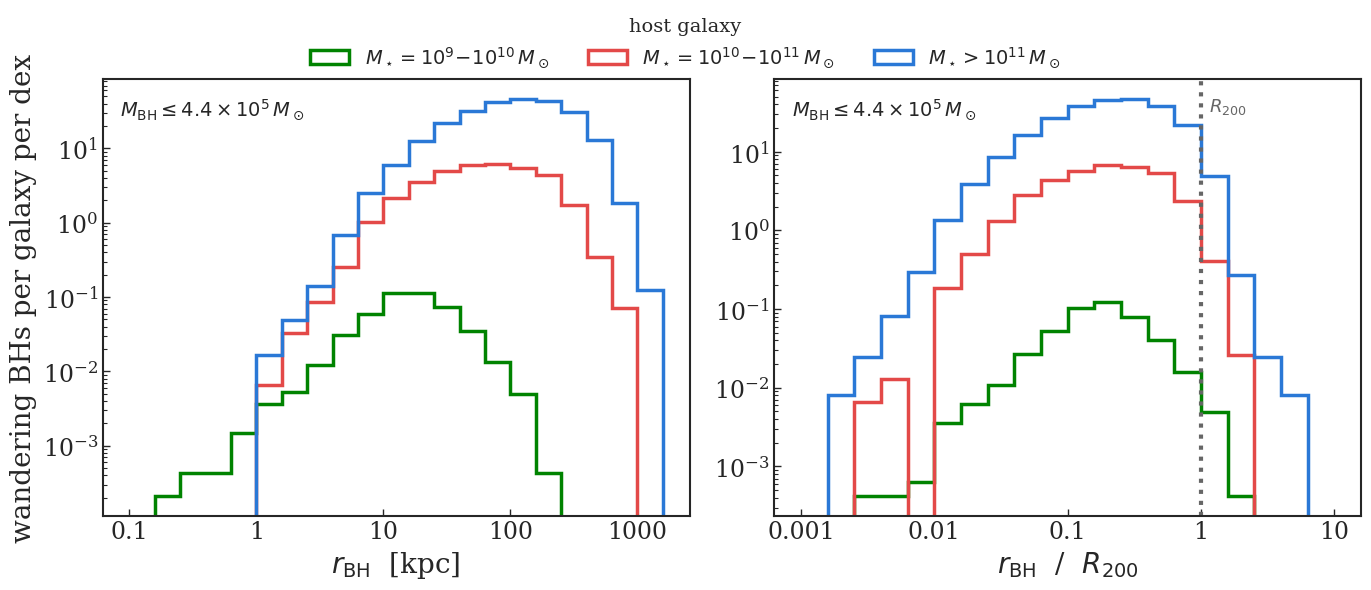

In [3]:
lr_bins = np.arange(-1.0, 3.21, 0.2)
lx_bins = np.arange(-3.0, 1.01, 0.2)

e = int(np.floor(np.log10(M_bh_max)))
m = M_bh_max / 10**e
mass_text = rf'$M_{{\rm BH}} \leq {m:.1f}\times10^{{{e}}}\,M_\odot$'

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for b in bins:
    sel = wand['massbin'] == b
    r = wand['dist_kpc'][sel]
    axes[0].hist(np.log10(r), bins=lr_bins, histtype='step', lw=2.5, color=color[b],
                 weights=np.full(r.size, 1.0 / ngal[b] / 0.2), label=label[b])
    x = x_r200[sel & np.isfinite(x_r200)]
    axes[1].hist(np.log10(x), bins=lx_bins, histtype='step', lw=2.5, color=color[b],
                 weights=np.full(x.size, 1.0 / ngal[b] / 0.2))
axes[1].axvline(0, color='0.4', lw=3, ls=':')
axes[1].text(0.06, 0.96, r'$R_{200}$', color='0.4', fontsize=13, va='top', transform=axes[1].get_xaxis_transform())
axes[0].set(yscale='log', xticks=[-1, 0, 1, 2, 3], xticklabels=['0.1', '1', '10', '100', '1000'],
            xlabel=r'$r_{\rm BH}$  [kpc]', ylabel='wandering BHs per galaxy per dex')
axes[1].set(yscale='log', xticks=[-3, -2, -1, 0, 1], xticklabels=['0.001', '0.01', '0.1', '1', '10'],
            xlabel=r'$r_{\rm BH}$  /  $R_{200}$')
for ax in axes:
    ax.text(0.03, 0.96, mass_text, fontsize=14, ha='left', va='top', transform=ax.transAxes)
    ax.grid(False)
fig.legend(*axes[0].get_legend_handles_labels(), loc='upper center', bbox_to_anchor=(0.5, 1.1), ncol=3,
           frameon=False, fontsize=14, title='host galaxy', title_fontsize=14)
fig.tight_layout()
fig.savefig('wandering_bh_distance_2panel.pdf', bbox_inches='tight')